# Population density per municipality

This notebook maps the population density of all Dutch municipalities.

Population density is strongly right-skewed: a few cities are far denser than the rest of the country. The regression therefore uses the natural logarithm of population density. For the same reason the map uses a logarithmic colour scale; otherwise almost all municipalities would get the same light colour.

**Required files:**
- `data/processed/population_density_per_municipality.csv`: population density and its logarithm per municipality, made by notebook 0.4
- `data/raw/gemeenten_2024.gpkg`: municipal boundaries from CBS/PDOK, 2024 municipal division
- `data/processed/chargingpoints_households_income.csv`: made by notebook 1, only used to check that the names match

**Output:**
- `figures/map_population_density_per_municipality.png`

In [1]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

## 1. Load the data

Notebook 0.4 has already prepared population density and its natural logarithm, with the same municipality names as the charging point file. We check that all names match the charging point data.

In [2]:
density = pd.read_csv("../data/processed/population_density_per_municipality.csv")

print("Number of municipalities:", len(density))
print("Missing values:", density["population_density"].isna().sum())
display(density["population_density"].describe().round(0))

# Check: does every municipality match the charging point data? Both lines should print set()
charging = pd.read_csv("../data/processed/chargingpoints_households_income.csv")
print("Only in the density data:", set(density["municipality"]) - set(charging["municipality"]))
print("Only in the charging data:", set(charging["municipality"]) - set(density["municipality"]))

Number of municipalities: 342
Missing values: 0


count     342.0
mean      918.0
std      1091.0
min        23.0
25%       249.0
50%       479.0
75%      1194.0
max      6868.0
Name: population_density, dtype: float64

Only in the density data: set()
Only in the charging data: set()


## 2. Distribution: why a logarithm?

The histogram on the left shows that most municipalities have fewer than 1,000 inhabitants per km², while a few cities have more than 5,000. After taking the logarithm (right) the distribution is much more symmetric.

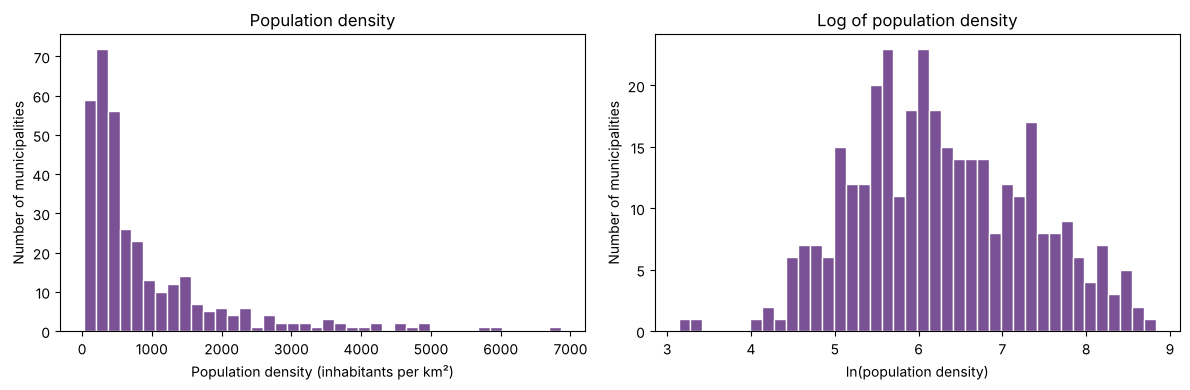

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(density["population_density"], bins=40, color="#7a5195", edgecolor="white")
axes[0].set_xlabel("Population density (inhabitants per km²)")
axes[0].set_ylabel("Number of municipalities")
axes[0].set_title("Population density")

axes[1].hist(density["log_population_density"], bins=40, color="#7a5195", edgecolor="white")
axes[1].set_xlabel("ln(population density)")
axes[1].set_ylabel("Number of municipalities")
axes[1].set_title("Log of population density")

plt.tight_layout()
plt.show()

## 3. Join the data to the map

The boundary file uses CBS names, for example *'s-Gravenhage* instead of *Den Haag*. We convert these to the spelling of the charging point file, so the map can be joined on the municipality name.

In [4]:
municipalities = gpd.read_file("../data/raw/gemeenten_2024.gpkg", layer="gemeente_gegeneraliseerd")

# Names in the boundary file (left) -> spelling of the charging point file (right)
map_name_mapping = {
    "'s-Gravenhage": "Den Haag",
    "Beek (L.)": "Beek",
    "Hengelo (O.)": "Hengelo",
    "Laren (NH.)": "Laren",
    "Middelburg (Z.)": "Middelburg",
    "Rijswijk (ZH.)": "Rijswijk",
    "Stein (L.)": "Stein",
}
municipalities["municipality"] = municipalities["statnaam"].replace(map_name_mapping)

map_gdf = municipalities.merge(density, on="municipality", how="left")

# Check: should print 0
print("Municipalities without data:", map_gdf["population_density"].isna().sum())

Municipalities without data: 0


## 4. Create the map

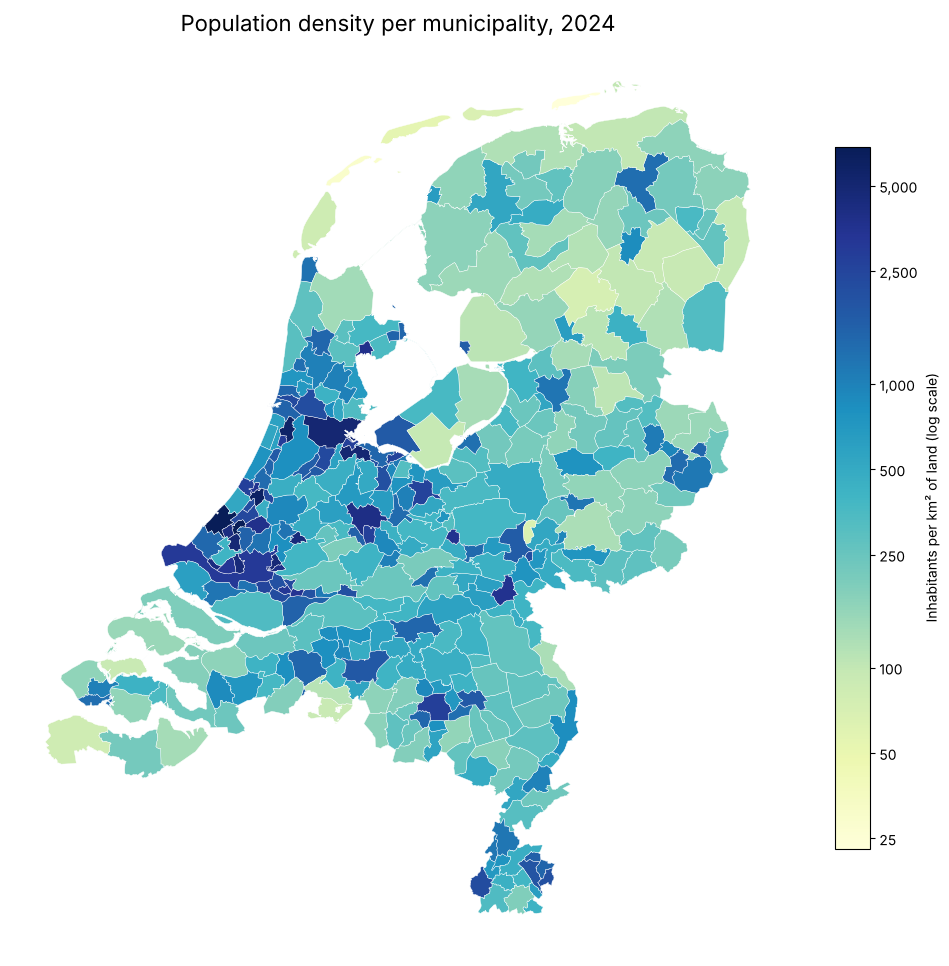

In [5]:
fig, ax = plt.subplots(figsize=(10, 12))

map_gdf.plot(
    column="population_density",
    cmap="YlGnBu",
    norm=LogNorm(vmin=map_gdf["population_density"].min(), vmax=map_gdf["population_density"].max()),
    linewidth=0.3,
    edgecolor="white",
    legend=True,
    legend_kwds={"label": "Inhabitants per km² of land (log scale)", "shrink": 0.6},
    ax=ax,
    missing_kwds={"color": "lightgrey", "label": "No data"},
)

# Readable numbers on the colour bar instead of 10^2 and 10^3
colorbar = fig.axes[-1]
ticks = [25, 50, 100, 250, 500, 1000, 2500, 5000]
colorbar.minorticks_off()
colorbar.set_yticks(ticks)
colorbar.set_yticklabels([f"{t:,}" for t in ticks])

ax.set_title("Population density per municipality, 2024", fontsize=16)
ax.axis("off")

plt.tight_layout()
os.makedirs("../figures", exist_ok=True)
plt.savefig("../figures/map_population_density_per_municipality.png", dpi=200)
plt.show()